# Viscosity model comparison - XGBoost vs others

Can batch process features predict Press 1 **Viscosity**, which model does it best, and which X matter?

- Data: `../Digester_Analysis/data/batch_master.csv` (1 row = 1 batch). **No PI access.**
- Validation: `TimeSeriesSplit` - always train on the past, test on the future. Gate = R² ≥ 0.30.
- **To add / remove a tag: edit `FEATURES` in `config.py`, then Restart & Run All.**
- Charts are saved to `output/` (git-ignored).

In [1]:
import importlib
import pandas as pd

import config, data, models, explain, plots
for mod in (config, data, models, explain, plots):   # pick up edits without restarting the kernel
    importlib.reload(mod)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

C:\Users\Predator\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Feature coverage
Every feature from `config.FEATURES`: does the column exist, and how many batches per digester have it?
Need a column name? Run `data.list_columns("alkali")`.

In [2]:
data.coverage()

rows: 1540 batches -> 447 with a Viscosity result after filters


,feature,label,status,pct_nan,n_D1,n_D2,n_D3,n_D4
0,alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,ok,0.0,108,125,129,85
1,alkali_accumulator2_conc_mean_hot_liquor_filling,Alkali conc 2,ok,0.0,108,125,129,85
2,pfactor_actual_last_prehydrolysis,P-factor,ok,0.0,108,125,129,85
3,heat_and_cook_minutes,H&C minutes,ok,0.0,108,125,129,85
4,white_liquor_per_ton_chip,WL / t chip,ok,0.0,108,125,129,85
5,liquor_to_wood_ratio,L:W,ok,0.0,108,125,129,85
6,LP_pressure_mean_heat_and_cook,LP pressure,ok,0.0,108,125,129,85
7,pfactor_rate,P-factor rate,ok,0.0,108,125,129,85
8,pfactor_temp_max_prehydrolysis,P-temp max,ok,0.0,108,125,129,85
9,mp_steam_valve_mean_prehydrolysis,MP valve (PH),ok,0.0,108,125,129,85


In [3]:
df, feats = data.build_xy()
feats

rows: 1540 batches -> 447 with a Viscosity result after filters
rows with all 13 features: 447  (2026-07-01 .. 2026-10-09)


['alkali_accumulator1_conc_mean_hot_liquor_filling',
 'alkali_accumulator2_conc_mean_hot_liquor_filling',
 'pfactor_actual_last_prehydrolysis',
 'heat_and_cook_minutes',
 'white_liquor_per_ton_chip',
 'liquor_to_wood_ratio',
 'LP_pressure_mean_heat_and_cook',
 'pfactor_rate',
 'pfactor_temp_max_prehydrolysis',
 'mp_steam_valve_mean_prehydrolysis',
 'is_D2',
 'is_D3',
 'is_D4']

## 2. Model leaderboard
Same rows, same time split for every model. `baseline` = predict the train mean (it can be < 0 when the mean drifts).

  scoring baseline       pooled
  scoring ridge          pooled
  scoring ridge          pooled + DigID
  scoring random_forest  pooled
  scoring random_forest  pooled + DigID
  scoring sklearn_gbm    pooled
  scoring sklearn_gbm    pooled + DigID
  scoring xgboost        pooled
  scoring xgboost        pooled + DigID
  saved c:\Users\Predator\dp-cooking-odl-analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\leaderboard.png


,model,type,features,R2,MAE,n_test,pass_gate
0,ridge,linear,pooled,0.213,29.4,356,False
1,ridge,linear,pooled + DigID,0.196,29.8,356,False
2,xgboost,trees (boosting),pooled,0.121,31.2,356,False
3,xgboost,trees (boosting),pooled + DigID,0.113,31.4,356,False
4,sklearn_gbm,trees (boosting),pooled,0.112,31.6,356,False
5,sklearn_gbm,trees (boosting),pooled + DigID,0.110,31.8,356,False
6,random_forest,trees (bagging),pooled + DigID,0.076,32.1,356,False
7,random_forest,trees (bagging),pooled,0.075,32.0,356,False
8,baseline,mean of train,pooled,-0.105,36.6,356,False


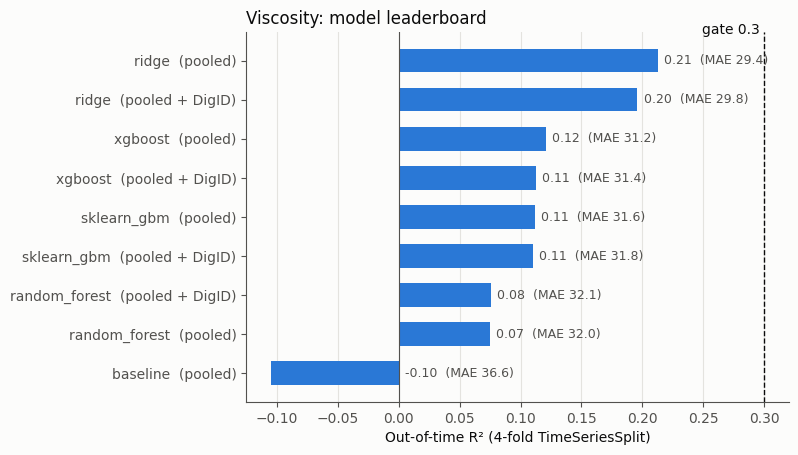

In [4]:
board = models.leaderboard(df, feats)
plots.leaderboard_bar(board)
board
#MAE (Mean Absolute Error) = ทายผิดเฉลี่ยกี่หน่วย
#R² (R-squared) = model อธิบายการแกว่งของ Viscosity ได้กี่เปอร์เซ็นต์

### Per-digester models (for comparison)
Each digester alone, process features only. Small n -> unstable; pooled is expected to win.

In [5]:
pd.concat([models.per_digester(df, feats, "ridge"), models.per_digester(df, feats, "xgboost")])

,digester,model,R2,MAE,n_batches,n_test
0,D1,ridge,-0.086,28.6,108,84
1,D2,ridge,0.143,32.7,125,100
2,D3,ridge,0.039,37.1,129,100
3,D4,ridge,0.266,24.8,85,68
0,D1,xgboost,-0.035,28.5,108,84
1,D2,xgboost,0.159,33.7,125,100
2,D3,xgboost,0.126,35.8,129,100
3,D4,xgboost,0.120,27.1,85,68


## 3. Feature effects - do the models agree?
- `direction` / `spearman`: sign of the link with Viscosity.
- `ridge_per_unit`: Viscosity change per 1 unit of X (linear, holding others fixed).
- `rf_perm`, `xgb_perm`: R² lost on the hold-out when X is shuffled.
- `xgb_shap`: mean |SHAP| in Viscosity units.
- `drop_one_dR2`: R² change when X is removed (negative = X helps).
- `rank`: mean rank of the four importance columns.

In [6]:
effects = explain.feature_effects(df, feats)
effects

  direction + ridge
  permutation importance (random forest, xgboost)
  SHAP (xgboost)
  drop-one (xgboost, time split)


,label,spearman,direction,ridge_per_unit,rf_perm,xgb_perm,xgb_shap,drop_one_dR2,rank
alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,-0.47,-,-17.658,0.037,0.061,8.8,-0.089,2.0
pfactor_actual_last_prehydrolysis,P-factor,-0.25,-,-0.178,0.038,0.079,14.5,0.014,3.6
mp_steam_valve_mean_prehydrolysis,MP valve (PH),-0.24,-,-2.455,0.027,0.066,4.8,0.011,4.5
heat_and_cook_minutes,H&C minutes,-0.33,-,-0.558,0.005,0.004,2.9,-0.021,5.6
LP_pressure_mean_heat_and_cook,LP pressure,0.04,+,-7.943,0.003,0.012,3.0,-0.014,5.6
white_liquor_per_ton_chip,WL / t chip,-0.10,-,-181.098,0.011,0.043,4.2,0.019,6.5
is_D3,D3,0.07,+,8.108,0.001,0.019,1.7,0.002,7.5
pfactor_rate,P-factor rate,-0.30,-,-2.681,0.016,-0.004,3.0,0.009,7.5
liquor_to_wood_ratio,L:W,0.13,+,12.363,0.005,-0.007,1.8,0.007,8.6
pfactor_temp_max_prehydrolysis,P-temp max,-0.23,-,-0.186,0.002,0.003,1.3,0.008,8.9


### SHAP summary (XGBoost, last 30% in time)
Each dot = one batch. Right = raises Viscosity; color = value of X (red high, blue low).

  saved c:\Users\Predator\dp-cooking-odl-analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\shap_summary.png


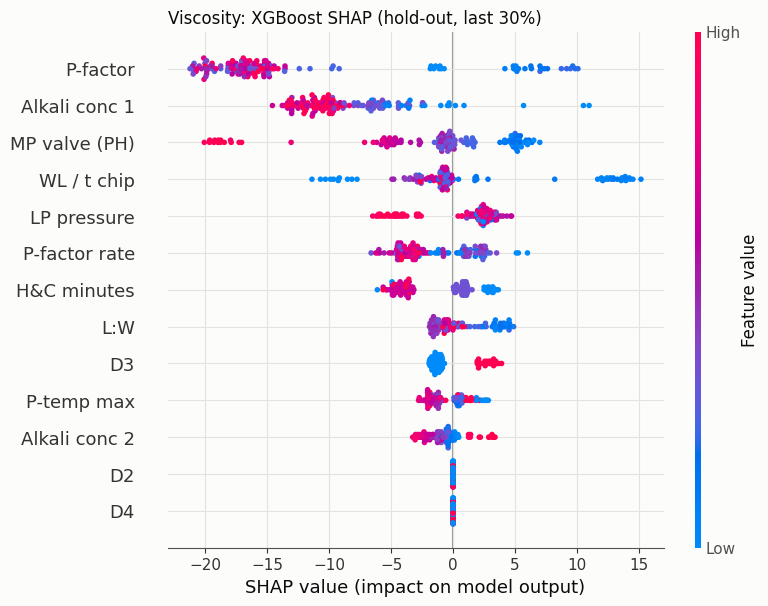

In [7]:
plots.shap_summary(df, feats);

### Partial dependence + plain binned means
PDP = model view; the quintile table = raw data view. They should tell the same story.

  saved c:\Users\Predator\dp-cooking-odl-analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\pdp_top.png
Alkali conc 1


,mean,count
alkali_accumulator1_conc_mean_hot_liquor_filling,,
"(34.781, 35.998]",804.7,90
"(35.998, 36.446]",802.2,89
"(36.446, 36.97]",791.5,89
"(36.97, 37.265]",783.7,89
"(37.265, 38.142]",752.5,90


P-factor


,mean,count
pfactor_actual_last_prehydrolysis,,
"(272.725, 315.432]",790.0,90
"(315.432, 331.619]",793.5,89
"(331.619, 342.585]",802.1,89
"(342.585, 361.333]",795.2,89
"(361.333, 509.527]",753.8,90


MP valve (PH)


,mean,count
mp_steam_valve_mean_prehydrolysis,,
"(6.834, 12.317]",795.7,90
"(12.317, 13.565]",799.7,89
"(13.565, 15.033]",782.4,89
"(15.033, 17.647]",786.2,91
"(17.647, 26.786]",770.1,88


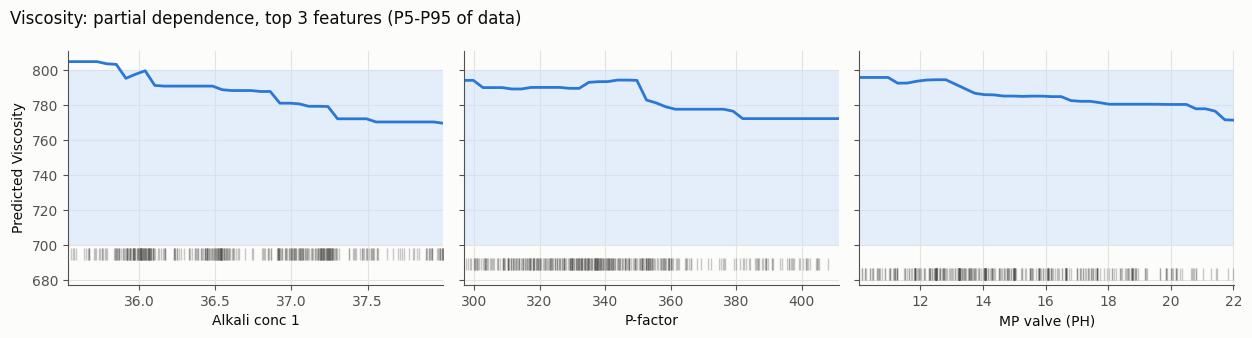

In [8]:
plots.pdp_top(df, feats, effects);
for f in [x for x in effects.index if not x.startswith("is_D")][:config.TOP_N_PDP]:
    print(data.label(f))
    display(explain.binned_means(df, f))

## 4. Actual vs predicted over time

  saved c:\Users\Predator\dp-cooking-odl-analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\pred_vs_actual_xgboost.png


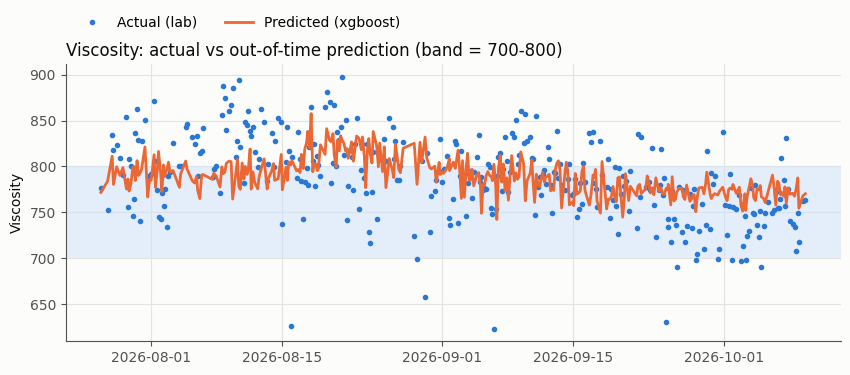

In [9]:
plots.predicted_vs_actual(df, models.time_split_predict(df, feats, "xgboost"), "xgboost");

## Reading the result
- Below the gate -> **do not optimize** on this model; use the feature table as hypotheses only.
- Trust a driver when several columns agree (sign + rank) and the binned means show the same shape.
- Log each run in `update.md` (What was done / Results / Found by).